
## Titanic Survival Prediction

### Problem Statement

The Titanic ship sank in 1912.

Based on passenger information such as:

- Age
- Gender
- Passenger Class

we want to predict whether a passenger survived or not.

In [2]:
# Import libraries

import pandas as pd

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score

In [3]:
# Load dataset

titanic = fetch_openml("titanic", version=1, as_frame=True)

df = titanic.frame

df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


## EDA – Exploratory Data Analysis
Understand the dataset before building a model.

In [5]:
# Check number of rows and columns

df.shape

(1309, 14)

In [6]:
# Check column names

df.columns

Index(['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket',
       'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest'],
      dtype='object')

In [7]:
# Check dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   pclass     1309 non-null   int64   
 1   survived   1309 non-null   category
 2   name       1309 non-null   object  
 3   sex        1309 non-null   category
 4   age        1046 non-null   float64 
 5   sibsp      1309 non-null   int64   
 6   parch      1309 non-null   int64   
 7   ticket     1309 non-null   object  
 8   fare       1308 non-null   float64 
 9   cabin      295 non-null    object  
 10  embarked   1307 non-null   category
 11  boat       486 non-null    object  
 12  body       121 non-null    float64 
 13  home.dest  745 non-null    object  
dtypes: category(3), float64(3), int64(3), object(5)
memory usage: 116.8+ KB


In [8]:
# Statistical summary

df.describe()

,pclass,age,sibsp,parch,fare,body
count,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,80.000000,8.000000,9.000000,512.329200,328.000000


In [9]:
# Check missing values

df.isnull().sum()

pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64

In [10]:
# Check survival counts

df["survived"].value_counts()

survived
0    809
1    500
Name: count, dtype: int64

## Visulization

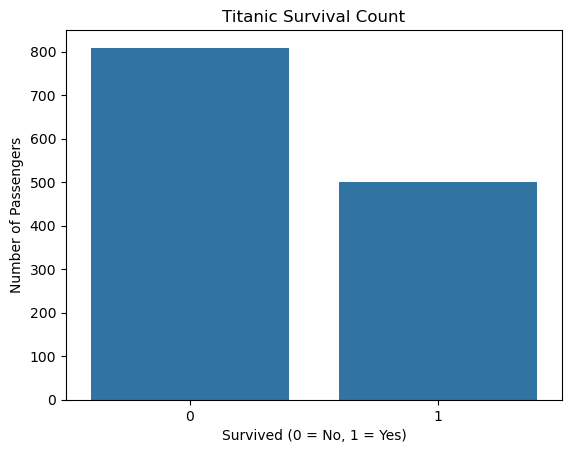

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

#Shows how many passengers survived and how many did not.
sns.countplot(data=df, x="survived")

plt.title("Titanic Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

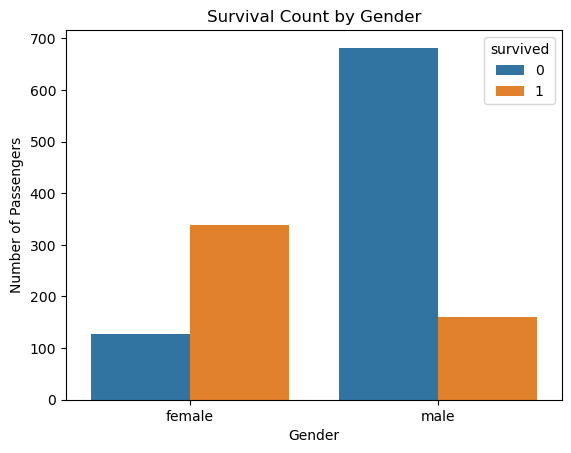

In [19]:
#Shows how many male and female passengers survived or did not survive.
sns.countplot(data=df, x="sex", hue="survived")

plt.title("Survival Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

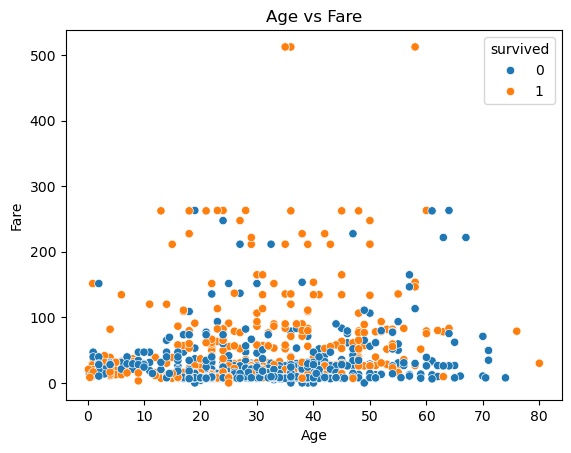

In [12]:
#Shows the relationship between passenger age and ticket fare.

sns.scatterplot(data=df, x="age", y="fare", hue="survived")

plt.title("Age vs Fare")
plt.xlabel("Age")
plt.ylabel("Fare")

plt.show()

## Feature Selection

In [15]:
#We don't need every column for our beginner model.
#We'll select useful features:

df = df[["survived", "pclass", "sex", "age", "fare", "sibsp", "parch"]]
df.head()

,survived,pclass,sex,age,fare,sibsp,parch
0,1,1,female,29.0000,211.3375,0,0
1,1,1,male,0.9167,151.5500,1,2
2,0,1,female,2.0000,151.5500,1,2
3,0,1,male,30.0000,151.5500,1,2
4,0,1,female,25.0000,151.5500,1,2


## Feature Engineering

Feature engineering means creating new useful features from existing columns.

Here, we'll create FamilySize.
- sibsp = Number of siblings/spouses aboard.
- parch = Number of parents/children aboard.

In [16]:
# Create a new feature

df["FamilySize"] = df["sibsp"] + df["parch"] + 1

df.head()

,survived,pclass,sex,age,fare,sibsp,parch,FamilySize
0,1,1,female,29.0000,211.3375,0,0,1
1,1,1,male,0.9167,151.5500,1,2,4
2,0,1,female,2.0000,151.5500,1,2,4
3,0,1,male,30.0000,151.5500,1,2,4
4,0,1,female,25.0000,151.5500,1,2,4


## Data Preprocessing

In [17]:
# Fill missing Age values

df["age"] = df["age"].fillna(df["age"].mean())

# Fill missing Fare values

df["fare"] = df["fare"].fillna(df["fare"].mean())

In [18]:
# Convert Sex into numerical values

le = LabelEncoder()

df["sex"] = le.fit_transform(df["sex"])

In [19]:
#Convert target into numeric values
df["survived"] = df["survived"].astype(int)

In [20]:
#Separate features and target

# Features

X = df.drop("survived", axis=1)

# Target

y = df["survived"]

## Train test split

80% data for training.
20% data for testing.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Model selection

In [25]:

# Create model

model = DecisionTreeClassifier(random_state=42)

# Train model

model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [26]:
#Make predictions

y_pred = model.predict(X_test)

y_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1])

In [28]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy*100,"%")

Model Accuracy: 76.33587786259542 %


In [29]:
# Compare actual and predicted values

results = pd.DataFrame({
    "Actual": y_test.iloc[:10].values,
    "Predicted": y_pred[:10]
})

results

,Actual,Predicted
0,0,0
1,1,0
2,0,0
3,0,0
4,0,0
5,1,0
6,0,0
7,1,0
8,0,0
9,1,1
